# Notebook Training: YOLOv8s-seg + Mask R-CNN + Mask2Former

<table>
  <tr><td><b>Nama</b></td><td>Shabrina Sarayati</td></tr>
  <tr><td><b>NRP</b></td><td>5054241009</td></tr>
  <tr><td><b>Mata Kuliah</b></td><td>Visi Komputer</td></tr>
</table>


## A. Setup & Download Datasetnya

In [1]:
# A1. Install semua library yang dibutuhkan
!pip install -q roboflow ultralytics transformers accelerate pycocotools pyyaml pandas

In [2]:
# A2. Mount ke Google Drive
import os
import gc
import json
import time
import random
import yaml
import numpy as np
import pandas as pd
import torch
from PIL import Image, ImageOps
from torch.utils.data import Dataset, DataLoader
from torch.utils.tensorboard import SummaryWriter
from google.colab import drive

drive.mount("/content/drive")

BASE_SAVE_DIR = "/content/drive/MyDrive/Visi Komputer/Tugas2/baseline_all_classes"
os.makedirs(BASE_SAVE_DIR, exist_ok=True)

def seed_everything(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

def free_gpu():
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

def load_coco_aligned_image(img_path, info):
    img = Image.open(img_path)
    expected_size = (int(info["width"]), int(info["height"]))
    if img.size == expected_size:
        return img.convert("RGB")
    img_t = ImageOps.exif_transpose(img)
    if img_t.size == expected_size:
        return img_t.convert("RGB")
    return img_t.convert("RGB").resize(expected_size, Image.BILINEAR)

seed_everything(42)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
gpu_name = torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU"
print("PyTorch:", torch.__version__, "| Device:", device, f"({gpu_name})")
print("Semua hasil akan disimpan ke:", BASE_SAVE_DIR)

Mounted at /content/drive
PyTorch: 2.14.1+cu130 | Device: cuda (Tesla T4)
Semua hasil akan disimpan ke: /content/drive/MyDrive/Visi Komputer/Tugas2/baseline_all_classes


In [ ]:
# A3. Download Dataset Panoptic Indoor Segmentation dari Roboflownya
from getpass import getpass
from roboflow import Roboflow

ROBOFLOW_API_KEY = getpass("API key roboflownya")
rf = Roboflow(api_key=ROBOFLOW_API_KEY)
project = rf.workspace("panopticindoor").project("panoptic-indoor-segmentation")
version = project.version(5)

dataset_yolo = version.download("yolov8", location="/content/dataset_yolov8")
dataset_coco = version.download("coco-segmentation", location="/content/dataset_coco")

# Perbaiki path data.yaml untuk YOLO
yaml_path = os.path.join(dataset_yolo.location, "data.yaml")
with open(yaml_path, "r") as f:
    data_cfg = yaml.safe_load(f)
data_cfg["path"] = dataset_yolo.location
data_cfg["train"] = "train/images"
data_cfg["val"] = "valid/images"
if os.path.exists(os.path.join(dataset_yolo.location, "test", "images")):
    data_cfg["test"] = "test/images"
with open(yaml_path, "w") as f:
    yaml.safe_dump(data_cfg, f, sort_keys=False)

print("YOLO dataset:", dataset_yolo.location)
print("COCO dataset:", dataset_coco.location)

## B: Model 1 - YOLOv8s-seg (One-Stage CNN)

In [4]:
# B1. Training & Evaluasi YOLOv8s-seg
from ultralytics import YOLO

SAVE_YOLO = os.path.join(BASE_SAVE_DIR, "01_yolov8s_seg")
os.makedirs(SAVE_YOLO, exist_ok=True)

t0 = time.time()
yolo_model = YOLO("yolov8s-seg.pt")
yolo_model.train(
    data=yaml_path,
    epochs=50,
    imgsz=640,
    batch=16,
    patience=15,
    project=SAVE_YOLO,
    name="train",
    exist_ok=True,
    save=True,
    plots=True,
    workers=2,
    seed=42,
)
yolo_sec = time.time() - t0

best_yolo = YOLO(os.path.join(SAVE_YOLO, "train", "weights", "best.pt"))
yolo_names = best_yolo.names

yolo_summary = []
for sp in ["val", "test"]:
    m = best_yolo.val(data=yaml_path, split=sp, imgsz=640, project=SAVE_YOLO, name=f"eval_{sp}", exist_ok=True)
    yolo_summary.append({
        "model": "YOLOv8s-seg",
        "split": "valid" if sp == "val" else "test",
        "mask_mAP50": round(float(m.seg.map50), 4),
        "mask_mAP50_95": round(float(m.seg.map), 4),
    })
    rows = []
    for idx, cid in enumerate(m.seg.ap_class_index):
        rows.append({
            "class_id": int(cid),
            "class_name": yolo_names[int(cid)],
            "mask_ap50": round(float(m.seg.ap50[idx]), 4),
            "mask_ap50_95": round(float(m.seg.ap[idx]), 4),
        })
    pd.DataFrame(rows).sort_values("mask_ap50_95").to_csv(
        os.path.join(SAVE_YOLO, f"per_class_ap_{'valid' if sp == 'val' else 'test'}.csv"),
        index=False,
    )

pd.DataFrame(yolo_summary).to_csv(os.path.join(SAVE_YOLO, "eval_summary.csv"), index=False)
with open(os.path.join(SAVE_YOLO, "gpu_time_log.json"), "w") as f:
    json.dump({"model": "YOLOv8s-seg", "gpu": gpu_name, "duration_seconds": round(yolo_sec, 2), "duration_minutes": round(yolo_sec / 60, 2)}, f, indent=2)

print(f"YOLOv8s-seg selesai dalam {yolo_sec/60:.2f} menit.")
print(pd.DataFrame(yolo_summary).to_string(index=False))

del yolo_model, best_yolo
free_gpu()

Ultralytics 8.4.216 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/dataset_yolov8/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8s-seg.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=train, nbs=64, nms=None, opset=None, optimize=False,

## C. Model 2 - Mask R-CNN (Two-Stage CNN)

In [5]:
# C1. Helper COCO Evaluation & Dataset Mask R-CNN
from pycocotools.coco import COCO
from pycocotools import mask as mask_utils
from pycocotools.cocoeval import COCOeval
from torchvision.transforms import functional as F
import torchvision
from torchvision.models.detection.mask_rcnn import MaskRCNN_ResNet50_FPN_V2_Weights, MaskRCNNPredictor
from torchvision.models.detection.faster_rcnn import FastRCNNPredictor

def compute_coco_metrics(coco_gt, coco_results, label_ids_order=None):
    if len(coco_results) == 0:
        return {"mask_mAP50_95": 0.0, "mask_mAP50": 0.0}, pd.DataFrame()
    coco_dt = coco_gt.loadRes(coco_results)
    coco_eval = COCOeval(coco_gt, coco_dt, iouType="segm")
    coco_eval.evaluate()
    coco_eval.accumulate()
    coco_eval.summarize()

    stats = {
        "mask_mAP50_95": round(float(coco_eval.stats[0]), 4),
        "mask_mAP50": round(float(coco_eval.stats[1]), 4),
    }
    precision = coco_eval.eval["precision"]
    rows = []
    for k, cid in enumerate(coco_eval.params.catIds):
        cname = coco_gt.cats[cid]["name"]
        p_all = precision[:, :, k, 0, 2]
        p_50 = precision[0, :, k, 0, 2]
        ap50_95 = float(np.mean(p_all[p_all > -1])) if np.any(p_all > -1) else np.nan
        ap50 = float(np.mean(p_50[p_50 > -1])) if np.any(p_50 > -1) else np.nan
        n_gt = len(coco_gt.getAnnIds(catIds=[cid]))
        rows.append({
            "class_id": int(cid),
            "class_name": cname,
            "gt_instances": int(n_gt),
            "mask_ap50": round(ap50, 4) if not np.isnan(ap50) else np.nan,
            "mask_ap50_95": round(ap50_95, 4) if not np.isnan(ap50_95) else np.nan,
        })
    return stats, pd.DataFrame(rows).sort_values("mask_ap50_95")

class CocoInstanceDataset(Dataset):
    def __init__(self, split_dir, cat_ids=None, filter_empty=False):
        self.split_dir = split_dir
        self.coco = COCO(os.path.join(split_dir, "_annotations.coco.json"))
        self.cat_ids = sorted(self.coco.getCatIds()) if cat_ids is None else cat_ids
        self.cat2label = {cid: i + 1 for i, cid in enumerate(self.cat_ids)}
        self.label2cat = {i + 1: cid for i, cid in enumerate(self.cat_ids)}

        all_img_ids = sorted(self.coco.getImgIds())
        if filter_empty:
            self.img_ids = [i for i in all_img_ids if len(self._extract_valid_anns(i)[0]) > 0]
        else:
            self.img_ids = all_img_ids

    def _extract_valid_anns(self, img_id):
        anns = self.coco.loadAnns(self.coco.getAnnIds(imgIds=img_id))
        boxes, labels, masks = [], [], []
        for ann in anns:
            if ann.get("iscrowd", 0) != 0 or ann["category_id"] not in self.cat2label:
                continue
            try:
                m = self.coco.annToMask(ann)
            except Exception:
                continue
            pos = np.where(m > 0)
            if len(pos[0]) == 0:
                continue
            ymin, ymax = int(np.min(pos[0])), int(np.max(pos[0]))
            xmin, xmax = int(np.min(pos[1])), int(np.max(pos[1]))
            if xmax <= xmin or ymax <= ymin:
                continue
            boxes.append([xmin, ymin, xmax, ymax])
            labels.append(self.cat2label[ann["category_id"]])
            masks.append(m.astype(np.uint8))
        return boxes, labels, masks

    def __len__(self):
        return len(self.img_ids)

    def __getitem__(self, idx):
        img_id = self.img_ids[idx]
        info = self.coco.loadImgs(img_id)[0]
        img = load_coco_aligned_image(os.path.join(self.split_dir, info["file_name"]), info)
        img_t = F.to_tensor(img)
        boxes, labels, masks = self._extract_valid_anns(img_id)
        if len(boxes) == 0:
            target = {
                "boxes": torch.zeros((0, 4), dtype=torch.float32),
                "labels": torch.zeros((0,), dtype=torch.int64),
                "masks": torch.zeros((0, img_t.shape[1], img_t.shape[2]), dtype=torch.uint8),
                "image_id": torch.tensor([img_id]),
            }
        else:
            target = {
                "boxes": torch.as_tensor(boxes, dtype=torch.float32),
                "labels": torch.as_tensor(labels, dtype=torch.int64),
                "masks": torch.as_tensor(np.stack(masks, axis=0), dtype=torch.uint8),
                "image_id": torch.tensor([img_id]),
            }
        return img_t, target

def mrcnn_collate(batch):
    return tuple(zip(*batch))

In [6]:
# C2. Training & Evaluasi Mask R-CNN
SAVE_MRCNN = os.path.join(BASE_SAVE_DIR, "02_maskrcnn")
os.makedirs(SAVE_MRCNN, exist_ok=True)
writer_mr = SummaryWriter(log_dir=os.path.join(SAVE_MRCNN, "tensorboard"))

mr_train_ds = CocoInstanceDataset(os.path.join(dataset_coco.location, "train"), filter_empty=True)
mr_valid_ds = CocoInstanceDataset(os.path.join(dataset_coco.location, "valid"), cat_ids=mr_train_ds.cat_ids)
mr_test_ds = CocoInstanceDataset(os.path.join(dataset_coco.location, "test"), cat_ids=mr_train_ds.cat_ids)

mr_train_loader = DataLoader(mr_train_ds, batch_size=4, shuffle=True, num_workers=2, collate_fn=mrcnn_collate)
mr_valid_loader = DataLoader(mr_valid_ds, batch_size=2, shuffle=False, num_workers=2, collate_fn=mrcnn_collate)
mr_test_loader = DataLoader(mr_test_ds, batch_size=2, shuffle=False, num_workers=2, collate_fn=mrcnn_collate)

num_classes_mr = len(mr_train_ds.cat_ids) + 1
mr_model = torchvision.models.detection.maskrcnn_resnet50_fpn_v2(weights=MaskRCNN_ResNet50_FPN_V2_Weights.DEFAULT)
in_f = mr_model.roi_heads.box_predictor.cls_score.in_features
mr_model.roi_heads.box_predictor = FastRCNNPredictor(in_f, num_classes_mr)
in_m = mr_model.roi_heads.mask_predictor.conv5_mask.in_channels
mr_model.roi_heads.mask_predictor = MaskRCNNPredictor(in_m, 256, num_classes_mr)
mr_model.to(device)

@torch.no_grad()
def eval_mrcnn(model, loader, ds, score_thresh=0.05):
    model.eval()
    coco_results = []
    for images, targets in loader:
        outputs = model([img.to(device) for img in images])
        for t, out in zip(targets, outputs):
            img_id = int(t["image_id"].item())
            for sc, lb, mk in zip(out["scores"].cpu().numpy(), out["labels"].cpu().numpy(), out["masks"].cpu().numpy()):
                if sc < score_thresh or int(lb) not in ds.label2cat:
                    continue
                bm = (mk[0] > 0.5).astype(np.uint8)
                if bm.sum() == 0:
                    continue
                rle = mask_utils.encode(np.asfortranarray(bm))
                rle["counts"] = rle["counts"].decode("utf-8")
                coco_results.append({"image_id": img_id, "category_id": int(ds.label2cat[int(lb)]), "segmentation": rle, "score": float(sc)})
    return compute_coco_metrics(ds.coco, coco_results)

EPOCHS_MR = 20
opt_mr = torch.optim.AdamW(mr_model.parameters(), lr=1e-4, weight_decay=1e-4)
sch_mr = torch.optim.lr_scheduler.CosineAnnealingLR(opt_mr, T_max=EPOCHS_MR)
scaler_mr = torch.amp.GradScaler("cuda", enabled=torch.cuda.is_available())

mr_history, best_mr_map = [], -1.0
best_mr_ckpt = os.path.join(SAVE_MRCNN, "best_maskrcnn.pth")
t0 = time.time()

for epoch in range(1, EPOCHS_MR + 1):
    mr_model.train()
    tot_loss, steps = 0.0, 0
    for images, targets in mr_train_loader:
        images = [img.to(device) for img in images]
        targets = [{k: v.to(device) for k, v in t.items()} for t in targets]
        opt_mr.zero_grad()
        with torch.amp.autocast("cuda", enabled=torch.cuda.is_available()):
            loss_dict = mr_model(images, targets)
            loss = sum(loss_dict.values())
        scaler_mr.scale(loss).backward()
        scaler_mr.step(opt_mr)
        scaler_mr.update()
        tot_loss += float(loss.item())
        steps += 1
    sch_mr.step()
    avg_loss = tot_loss / max(steps, 1)
    writer_mr.add_scalar("train/loss", avg_loss, epoch)

    v_map, v_map50 = np.nan, np.nan
    if epoch % 2 == 0 or epoch == EPOCHS_MR:
        st, _ = eval_mrcnn(mr_model, mr_valid_loader, mr_valid_ds)
        v_map, v_map50 = st["mask_mAP50_95"], st["mask_mAP50"]
        writer_mr.add_scalar("val/mask_mAP50_95", v_map, epoch)
        writer_mr.add_scalar("val/mask_mAP50", v_map50, epoch)
        if v_map > best_mr_map:
            best_mr_map = v_map
            torch.save(mr_model.state_dict(), best_mr_ckpt)

    mr_history.append({"epoch": epoch, "train_loss": round(avg_loss, 4), "val_mask_mAP50": None if np.isnan(v_map50) else v_map50, "val_mask_mAP50_95": None if np.isnan(v_map) else v_map, "elapsed_sec": round(time.time() - t0, 1)})
    pd.DataFrame(mr_history).to_csv(os.path.join(SAVE_MRCNN, "results.csv"), index=False)
    print(f"[Mask R-CNN] Epoch {epoch:02d}/{EPOCHS_MR} | loss={avg_loss:.4f} | val_mAP={v_map}")

mr_sec = time.time() - t0
writer_mr.close()

mr_model.load_state_dict(torch.load(best_mr_ckpt, map_location=device))
mr_summary = []
for sp_name, ldr, ds in [("valid", mr_valid_loader, mr_valid_ds), ("test", mr_test_loader, mr_test_ds)]:
    st, df_c = eval_mrcnn(mr_model, ldr, ds)
    mr_summary.append({"model": "Mask R-CNN", "split": sp_name, **st})
    df_c.to_csv(os.path.join(SAVE_MRCNN, f"per_class_ap_{sp_name}.csv"), index=False)

pd.DataFrame(mr_summary).to_csv(os.path.join(SAVE_MRCNN, "eval_summary.csv"), index=False)
with open(os.path.join(SAVE_MRCNN, "gpu_time_log.json"), "w") as f:
    json.dump({"model": "Mask R-CNN", "gpu": gpu_name, "duration_seconds": round(mr_sec, 2), "duration_minutes": round(mr_sec / 60, 2)}, f, indent=2)

print(f"Mask R-CNN selesai dalam {mr_sec/60:.2f} menit.")
print(pd.DataFrame(mr_summary).to_string(index=False))

del mr_model, opt_mr, sch_mr, scaler_mr
free_gpu()

loading annotations into memory...
Done (t=0.06s)
creating index...
index created!
loading annotations into memory...
Done (t=0.05s)
creating index...
index created!
loading annotations into memory...
Done (t=0.10s)
creating index...
index created!
Downloading: "https://download.pytorch.org/models/maskrcnn_resnet50_fpn_v2_coco-73cbd019.pth" to /root/.cache/torch/hub/checkpoints/maskrcnn_resnet50_fpn_v2_coco-73cbd019.pth


100%|██████████| 177M/177M [00:01<00:00, 162MB/s]


[Mask R-CNN] Epoch 01/20 | loss=2.1599 | val_mAP=nan
Loading and preparing results...
DONE (t=0.22s)
creating index...
index created!
Running per image evaluation...
Evaluate annotation type *segm*
DONE (t=2.22s).
Accumulating evaluation results...
DONE (t=0.73s).
 Average Precision  (AP) @[ IoU=0.50:0.95 | area=   all | maxDets=100 ] = 0.086
 Average Precision  (AP) @[ IoU=0.50      | area=   all | maxDets=100 ] = 0.146
 Average Precision  (AP) @[ IoU=0.75      | area=   all | maxDets=100 ] = 0.088
 Average Precision  (AP) @[ IoU=0.50:0.95 | area= small | maxDets=100 ] = 0.031
 Average Precision  (AP) @[ IoU=0.50:0.95 | area=medium | maxDets=100 ] = 0.070
 Average Precision  (AP) @[ IoU=0.50:0.95 | area= large | maxDets=100 ] = 0.114
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDets=  1 ] = 0.069
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDets= 10 ] = 0.161
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDets=100 ] = 0.169
 Average Recall

## D: Model 3 - Mask2Former (Transformer)

In [7]:
# D1. Dataset, Training & Evaluasi Mask2Former
from transformers import Mask2FormerImageProcessor, Mask2FormerForUniversalSegmentation

SAVE_M2F = os.path.join(BASE_SAVE_DIR, "03_mask2former")
os.makedirs(SAVE_M2F, exist_ok=True)
writer_m2f = SummaryWriter(log_dir=os.path.join(SAVE_M2F, "tensorboard"))

M2F_CKPT = "facebook/mask2former-swin-tiny-coco-instance"
IGNORE_IDX = 255

class Mask2FormerCocoDataset(Dataset):
    def __init__(self, split_dir, cat_ids=None, filter_empty=False):
        self.split_dir = split_dir
        self.coco = COCO(os.path.join(split_dir, "_annotations.coco.json"))
        self.cat_ids = sorted(self.coco.getCatIds()) if cat_ids is None else cat_ids
        self.cat2label = {cid: i for i, cid in enumerate(self.cat_ids)}
        self.label2cat = {i: cid for i, cid in enumerate(self.cat_ids)}
        all_img_ids = sorted(self.coco.getImgIds())
        if filter_empty:
            self.img_ids = [i for i in all_img_ids if self._count_valid(i) > 0]
        else:
            self.img_ids = all_img_ids

    def _build_seg_map(self, img_id, w, h):
        anns = self.coco.loadAnns(self.coco.getAnnIds(imgIds=img_id))
        parsed = []
        for ann in anns:
            if ann.get("iscrowd", 0) != 0 or ann["category_id"] not in self.cat2label:
                continue
            try:
                m = self.coco.annToMask(ann)
            except Exception:
                continue
            area = int(m.sum())
            if area > 0 and m.shape == (h, w):
                parsed.append((area, self.cat2label[ann["category_id"]], m))
        parsed.sort(key=lambda x: x[0], reverse=True)
        seg_map = np.full((h, w), IGNORE_IDX, dtype=np.int32)
        inst2sem, inst_id = {}, 1
        for _, lid, m in parsed:
            if inst_id == IGNORE_IDX:
                inst_id += 1
            seg_map[m > 0] = inst_id
            inst2sem[inst_id] = lid
            inst_id += 1
        present = set(np.unique(seg_map).tolist())
        inst2sem = {k: v for k, v in inst2sem.items() if k in present and k != IGNORE_IDX}
        return seg_map, inst2sem

    def _count_valid(self, img_id):
        info = self.coco.loadImgs(img_id)[0]
        return len(self._build_seg_map(img_id, info["width"], info["height"])[1])

    def __len__(self):
        return len(self.img_ids)

    def __getitem__(self, idx):
        img_id = self.img_ids[idx]
        info = self.coco.loadImgs(img_id)[0]
        img = load_coco_aligned_image(os.path.join(self.split_dir, info["file_name"]), info)
        w, h = img.size
        seg_map, inst2sem = self._build_seg_map(img_id, w, h)
        return {"image": img, "seg_map": seg_map, "inst2sem": inst2sem, "image_id": img_id, "orig_size": (h, w)}

m2f_train_ds = Mask2FormerCocoDataset(os.path.join(dataset_coco.location, "train"), filter_empty=True)
m2f_valid_ds = Mask2FormerCocoDataset(os.path.join(dataset_coco.location, "valid"), cat_ids=m2f_train_ds.cat_ids)
m2f_test_ds = Mask2FormerCocoDataset(os.path.join(dataset_coco.location, "test"), cat_ids=m2f_train_ds.cat_ids)

id2label = {i: m2f_train_ds.coco.cats[cid]["name"] for i, cid in enumerate(m2f_train_ds.cat_ids)}
label2id = {v: k for k, v in id2label.items()}

processor = Mask2FormerImageProcessor(ignore_index=IGNORE_IDX, do_reduce_labels=False, size={"height": 512, "width": 512}, do_resize=True)

def m2f_train_collate(batch):
    return processor(images=[b["image"] for b in batch], segmentation_maps=[b["seg_map"] for b in batch], instance_id_to_semantic_id=[b["inst2sem"] for b in batch], return_tensors="pt")

def m2f_eval_collate(batch):
    inp = processor(images=[b["image"] for b in batch], return_tensors="pt")
    inp["image_ids"] = [b["image_id"] for b in batch]
    inp["orig_sizes"] = [b["orig_size"] for b in batch]
    return inp

m2f_train_loader = DataLoader(m2f_train_ds, batch_size=4, shuffle=True, num_workers=2, collate_fn=m2f_train_collate)
m2f_valid_loader = DataLoader(m2f_valid_ds, batch_size=2, shuffle=False, num_workers=2, collate_fn=m2f_eval_collate)
m2f_test_loader = DataLoader(m2f_test_ds, batch_size=2, shuffle=False, num_workers=2, collate_fn=m2f_eval_collate)

m2f_model = Mask2FormerForUniversalSegmentation.from_pretrained(M2F_CKPT, id2label=id2label, label2id=label2id, ignore_mismatched_sizes=True).to(device)

@torch.no_grad()
def eval_m2f(model, loader, ds, threshold=0.3):
    model.eval()
    coco_results = []
    for batch in loader:
        outputs = model(pixel_values=batch["pixel_values"].to(device), pixel_mask=batch["pixel_mask"].to(device))
        results = processor.post_process_instance_segmentation(outputs, threshold=threshold, target_sizes=batch["orig_sizes"])
        for img_id, res in zip(batch["image_ids"], results):
            seg = res["segmentation"].cpu().numpy()
            for info in res["segments_info"]:
                lbl = int(info["label_id"])
                if lbl not in ds.label2cat:
                    continue
                bm = (seg == info["id"]).astype(np.uint8)
                if bm.sum() == 0:
                    continue
                rle = mask_utils.encode(np.asfortranarray(bm))
                rle["counts"] = rle["counts"].decode("utf-8")
                coco_results.append({"image_id": int(img_id), "category_id": int(ds.label2cat[lbl]), "segmentation": rle, "score": float(info["score"])})
    return compute_coco_metrics(ds.coco, coco_results)

EPOCHS_M2F = 20
opt_m2f = torch.optim.AdamW(m2f_model.parameters(), lr=5e-5, weight_decay=1e-4)
sch_m2f = torch.optim.lr_scheduler.CosineAnnealingLR(opt_m2f, T_max=EPOCHS_M2F)
scaler_m2f = torch.amp.GradScaler("cuda", enabled=torch.cuda.is_available())

m2f_history, best_m2f_map = [], -1.0
best_m2f_dir = os.path.join(SAVE_M2F, "best_mask2former")
t0 = time.time()

for epoch in range(1, EPOCHS_M2F + 1):
    m2f_model.train()
    tot_loss, steps = 0.0, 0
    for batch in m2f_train_loader:
        opt_m2f.zero_grad()
        with torch.amp.autocast("cuda", enabled=torch.cuda.is_available()):
            outputs = m2f_model(
                pixel_values=batch["pixel_values"].to(device),
                pixel_mask=batch["pixel_mask"].to(device),
                mask_labels=[m.to(device) for m in batch["mask_labels"]],
                class_labels=[c.to(device) for c in batch["class_labels"]],
            )
            loss = outputs.loss
        scaler_m2f.scale(loss).backward()
        scaler_m2f.unscale_(opt_m2f)
        torch.nn.utils.clip_grad_norm_(m2f_model.parameters(), 1.0)
        scaler_m2f.step(opt_m2f)
        scaler_m2f.update()
        tot_loss += float(loss.item())
        steps += 1
    sch_m2f.step()
    avg_loss = tot_loss / max(steps, 1)
    writer_m2f.add_scalar("train/loss", avg_loss, epoch)

    v_map, v_map50 = np.nan, np.nan
    if epoch % 2 == 0 or epoch == EPOCHS_M2F:
        st, _ = eval_m2f(m2f_model, m2f_valid_loader, m2f_valid_ds)
        v_map, v_map50 = st["mask_mAP50_95"], st["mask_mAP50"]
        writer_m2f.add_scalar("val/mask_mAP50_95", v_map, epoch)
        writer_m2f.add_scalar("val/mask_mAP50", v_map50, epoch)
        if v_map > best_m2f_map:
            best_m2f_map = v_map
            m2f_model.save_pretrained(best_m2f_dir)
            processor.save_pretrained(best_m2f_dir)

    m2f_history.append({"epoch": epoch, "train_loss": round(avg_loss, 4), "val_mask_mAP50": None if np.isnan(v_map50) else v_map50, "val_mask_mAP50_95": None if np.isnan(v_map) else v_map, "elapsed_sec": round(time.time() - t0, 1)})
    pd.DataFrame(m2f_history).to_csv(os.path.join(SAVE_M2F, "results.csv"), index=False)
    print(f"[Mask2Former] Epoch {epoch:02d}/{EPOCHS_M2F} | loss={avg_loss:.4f} | val_mAP={v_map}")

m2f_sec = time.time() - t0
writer_m2f.close()

best_m2f = Mask2FormerForUniversalSegmentation.from_pretrained(best_m2f_dir).to(device)
m2f_summary = []
for sp_name, ldr, ds in [("valid", m2f_valid_loader, m2f_valid_ds), ("test", m2f_test_loader, m2f_test_ds)]:
    st, df_c = eval_m2f(best_m2f, ldr, ds)
    m2f_summary.append({"model": "Mask2Former", "split": sp_name, **st})
    df_c.to_csv(os.path.join(SAVE_M2F, f"per_class_ap_{sp_name}.csv"), index=False)

pd.DataFrame(m2f_summary).to_csv(os.path.join(SAVE_M2F, "eval_summary.csv"), index=False)
with open(os.path.join(SAVE_M2F, "gpu_time_log.json"), "w") as f:
    json.dump({"model": "Mask2Former", "gpu": gpu_name, "duration_seconds": round(m2f_sec, 2), "duration_minutes": round(m2f_sec / 60, 2)}, f, indent=2)

print(f"Mask2Former selesai dalam {m2f_sec/60:.2f} menit.")
print(pd.DataFrame(m2f_summary).to_string(index=False))

del m2f_model, best_m2f, opt_m2f, sch_m2f, scaler_m2f
free_gpu()

loading annotations into memory...
Done (t=0.04s)
creating index...
index created!
loading annotations into memory...
Done (t=0.02s)
creating index...
index created!
loading annotations into memory...
Done (t=0.07s)
creating index...
index created!


config.json:   0%|          | 0.00/79.8k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  190MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/554 [00:00<?, ?it/s]

[transformers] Mask2FormerForUniversalSegmentation LOAD REPORT from: facebook/mask2former-swin-tiny-coco-instance
Key                                                                                                                                | Status     |                                                                                         
-----------------------------------------------------------------------------------------------------------------------------------+------------+-----------------------------------------------------------------------------------------
model.pixel_level_module.encoder.swin.encoder.layers.{0, 1, 2, 3}.blocks.{0, 1, 2, 3, 4, 5}.attention.self.relative_position_index | UNEXPECTED |                                                                                         
model.pixel_level_module.encoder.swin.layernorm.weight                                                                             | MISSING    |                                    

... (17 outputs left out)

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

[Mask2Former] Epoch 20/20 | loss=16.0927 | val_mAP=0.1922


Loading weights:   0%|          | 0/556 [00:00<?, ?it/s]

Loading and preparing results...
DONE (t=0.07s)
creating index...
index created!
Running per image evaluation...
Evaluate annotation type *segm*
DONE (t=2.06s).
Accumulating evaluation results...
DONE (t=0.73s).
 Average Precision  (AP) @[ IoU=0.50:0.95 | area=   all | maxDets=100 ] = 0.192
 Average Precision  (AP) @[ IoU=0.50      | area=   all | maxDets=100 ] = 0.259
 Average Precision  (AP) @[ IoU=0.75      | area=   all | maxDets=100 ] = 0.202
 Average Precision  (AP) @[ IoU=0.50:0.95 | area= small | maxDets=100 ] = 0.032
 Average Precision  (AP) @[ IoU=0.50:0.95 | area=medium | maxDets=100 ] = 0.139
 Average Precision  (AP) @[ IoU=0.50:0.95 | area= large | maxDets=100 ] = 0.252
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDets=  1 ] = 0.147
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDets= 10 ] = 0.234
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDets=100 ] = 0.239
 Average Recall     (AR) @[ IoU=0.50:0.95 | area= small | maxDets=10

## E: Gabungan Hasil & Analisis Awal Penentuan 3 Kelas paling Susah

In [8]:
# E1. Rekapitulasi Performa & Waktu GPU Ketiga Model + Gabungan AP Per Kelas
summary_files = [
    os.path.join(BASE_SAVE_DIR, "01_yolov8s_seg", "eval_summary.csv"),
    os.path.join(BASE_SAVE_DIR, "02_maskrcnn", "eval_summary.csv"),
    os.path.join(BASE_SAVE_DIR, "03_mask2former", "eval_summary.csv"),
]
all_sum = pd.concat([pd.read_csv(f) for f in summary_files if os.path.exists(f)], ignore_index=True)
print("=== RINGKASAN EVALUASI SEMUA MODEL ===")
print(all_sum.to_string(index=False))

gpu_files = [
    os.path.join(BASE_SAVE_DIR, "01_yolov8s_seg", "gpu_time_log.json"),
    os.path.join(BASE_SAVE_DIR, "02_maskrcnn", "gpu_time_log.json"),
    os.path.join(BASE_SAVE_DIR, "03_mask2former", "gpu_time_log.json"),
]
gpu_logs = [json.load(open(f)) for f in gpu_files if os.path.exists(f)]
print("\n=== CATATAN WAKTU GPU ===")
print(pd.DataFrame(gpu_logs).to_string(index=False))

# Gabungkan AP50-95 per kelas di TEST split untuk mencari kandidat 3 kelas tersulit
ap_paths = {
    "yolo": os.path.join(BASE_SAVE_DIR, "01_yolov8s_seg", "per_class_ap_test.csv"),
    "mrcnn": os.path.join(BASE_SAVE_DIR, "02_maskrcnn", "per_class_ap_test.csv"),
    "m2f": os.path.join(BASE_SAVE_DIR, "03_mask2former", "per_class_ap_test.csv"),
}
if all(os.path.exists(p) for p in ap_paths.values()):
    df_y = pd.read_csv(ap_paths["yolo"])[["class_name", "mask_ap50_95"]].rename(columns={"mask_ap50_95": "yolo_ap"})
    df_r = pd.read_csv(ap_paths["mrcnn"])[["class_name", "gt_instances", "mask_ap50_95"]].rename(columns={"mask_ap50_95": "mrcnn_ap"})
    df_m = pd.read_csv(ap_paths["m2f"])[["class_name", "mask_ap50_95"]].rename(columns={"mask_ap50_95": "m2f_ap"})

    merged = df_r.merge(df_m, on="class_name", how="left").merge(df_y, on="class_name", how="left")
    merged["mean_ap"] = merged[["yolo_ap", "mrcnn_ap", "m2f_ap"]].mean(axis=1)
    # Filter kelas yang muncul signifikan di test set (mis. gt_instances >= 10) agar tidak memilih kelas kosong/zero-shot
    cand = merged[merged["gt_instances"] >= 10].sort_values("mean_ap", ascending=True)
    merged.to_csv(os.path.join(BASE_SAVE_DIR, "combined_per_class_ap_test.csv"), index=False)

    print("\n=== KANDIDAT KELAS TERSULIT (Test GT >= 10, Diurutkan dari Mean AP Terendah) ===")
    print(cand.head(15).to_string(index=False))

=== RINGKASAN EVALUASI SEMUA MODEL ===
      model split  mask_mAP50  mask_mAP50_95
YOLOv8s-seg valid      0.3467         0.2452
YOLOv8s-seg  test      0.1971         0.1279
 Mask R-CNN valid      0.2782         0.1908
 Mask R-CNN  test      0.1650         0.1082
Mask2Former valid      0.2593         0.1922
Mask2Former  test      0.1419         0.0964

=== CATATAN WAKTU GPU ===
      model      gpu  duration_seconds  duration_minutes
YOLOv8s-seg Tesla T4           1056.34             17.61
 Mask R-CNN Tesla T4           2097.97             34.97
Mask2Former Tesla T4           1833.80             30.56

=== KANDIDAT KELAS TERSULIT (Test GT >= 10, Diurutkan dari Mean AP Terendah) ===
  class_name  gt_instances  mrcnn_ap  m2f_ap  yolo_ap  mean_ap
   cardboard            14    0.0000  0.0000   0.0000 0.000000
  toothbrush            14    0.0000  0.0000   0.0000 0.000000
paper-merged            51    0.0000  0.0000   0.0016 0.000533
mirror-stuff            34    0.0000  0.0000   0.0057 0.0

Mounted at /content/drive


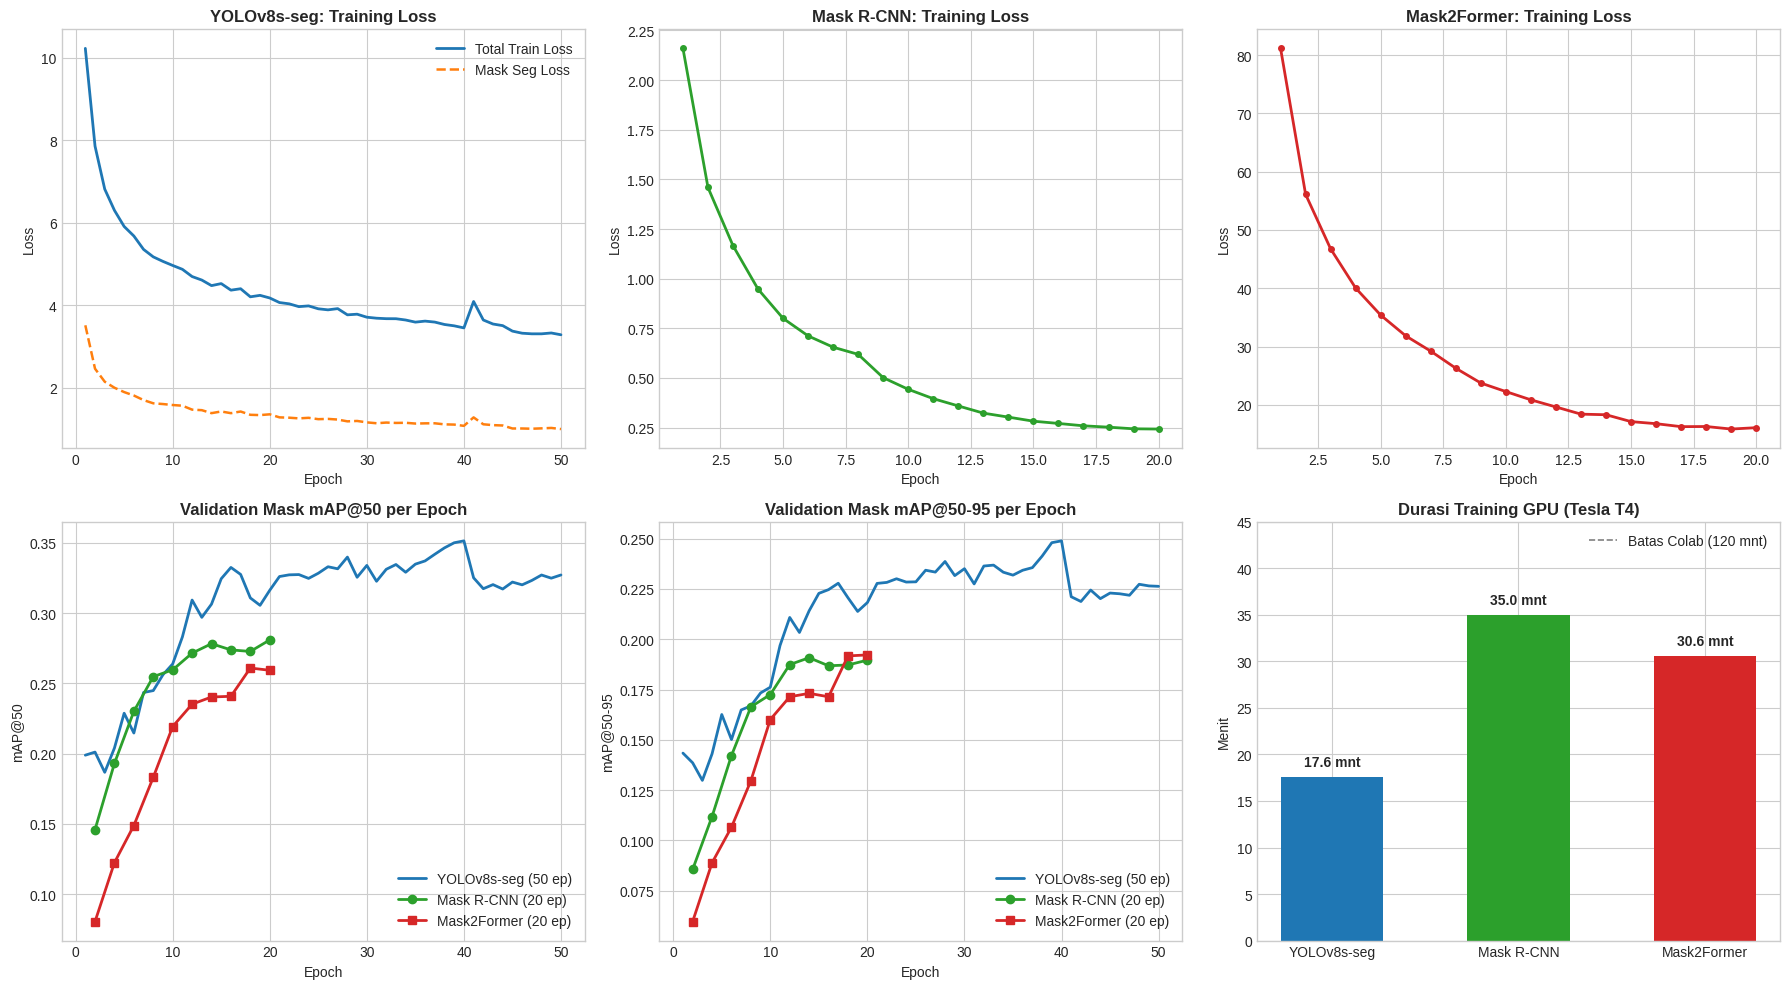

Disimpan: /content/drive/MyDrive/Visi Komputer/Tugas2/baseline_all_classes/visualizations/training_curves_all_models.png


In [1]:
# F1. Visualisasi Kurva Training (Loss & Validation Mask mAP per Epoch) + Waktu GPU
import os
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from google.colab import drive

if not os.path.exists("/content/drive/MyDrive"):
    drive.mount("/content/drive")

BASE_SAVE_DIR = "/content/drive/MyDrive/Visi Komputer/Tugas2/baseline_all_classes"
VIZ_DIR = os.path.join(BASE_SAVE_DIR, "visualizations")
os.makedirs(VIZ_DIR, exist_ok=True)

# 1. Baca results.csv masing-masing model
df_yolo = pd.read_csv(os.path.join(BASE_SAVE_DIR, "01_yolov8s_seg", "train", "results.csv"))
df_yolo.columns = df_yolo.columns.str.strip()
df_yolo["total_train_loss"] = (
    df_yolo["train/box_loss"] + df_yolo["train/seg_loss"] + df_yolo["train/cls_loss"] + df_yolo["train/dfl_loss"]
)

df_mrcnn = pd.read_csv(os.path.join(BASE_SAVE_DIR, "02_maskrcnn", "results.csv"))
df_m2f = pd.read_csv(os.path.join(BASE_SAVE_DIR, "03_mask2former", "results.csv"))

plt.style.use("seaborn-v0_8-whitegrid")
fig, axes = plt.subplots(2, 3, figsize=(18, 10))

# Row 1: Kurva Train Loss tiap model (skala y masing-masing karena formula loss berbeda)
axes[0, 0].plot(df_yolo["epoch"], df_yolo["total_train_loss"], color="#1f77b4", lw=2, label="Total Train Loss")
axes[0, 0].plot(df_yolo["epoch"], df_yolo["train/seg_loss"], color="#ff7f0e", lw=1.8, linestyle="--", label="Mask Seg Loss")
axes[0, 0].set_title("YOLOv8s-seg: Training Loss", fontsize=12, fontweight="bold")
axes[0, 0].set_xlabel("Epoch")
axes[0, 0].set_ylabel("Loss")
axes[0, 0].legend()

axes[0, 1].plot(df_mrcnn["epoch"], df_mrcnn["train_loss"], color="#2ca02c", lw=2, marker="o", markersize=4)
axes[0, 1].set_title("Mask R-CNN: Training Loss", fontsize=12, fontweight="bold")
axes[0, 1].set_xlabel("Epoch")
axes[0, 1].set_ylabel("Loss")

axes[0, 2].plot(df_m2f["epoch"], df_m2f["train_loss"], color="#d62728", lw=2, marker="o", markersize=4)
axes[0, 2].set_title("Mask2Former: Training Loss", fontsize=12, fontweight="bold")
axes[0, 2].set_xlabel("Epoch")
axes[0, 2].set_ylabel("Loss")

# Row 2 Col 0 & 1: Perbandingan kurva Validation mAP@50 & mAP@50-95
mr_val = df_mrcnn.dropna(subset=["val_mask_mAP50"])
m2f_val = df_m2f.dropna(subset=["val_mask_mAP50"])

axes[1, 0].plot(df_yolo["epoch"], df_yolo["metrics/mAP50(M)"], label="YOLOv8s-seg (50 ep)", color="#1f77b4", lw=2)
axes[1, 0].plot(mr_val["epoch"], mr_val["val_mask_mAP50"], label="Mask R-CNN (20 ep)", color="#2ca02c", lw=2, marker="o")
axes[1, 0].plot(m2f_val["epoch"], m2f_val["val_mask_mAP50"], label="Mask2Former (20 ep)", color="#d62728", lw=2, marker="s")
axes[1, 0].set_title("Validation Mask mAP@50 per Epoch", fontsize=12, fontweight="bold")
axes[1, 0].set_xlabel("Epoch")
axes[1, 0].set_ylabel("mAP@50")
axes[1, 0].legend()

axes[1, 1].plot(df_yolo["epoch"], df_yolo["metrics/mAP50-95(M)"], label="YOLOv8s-seg (50 ep)", color="#1f77b4", lw=2)
axes[1, 1].plot(mr_val["epoch"], mr_val["val_mask_mAP50_95"], label="Mask R-CNN (20 ep)", color="#2ca02c", lw=2, marker="o")
axes[1, 1].plot(m2f_val["epoch"], m2f_val["val_mask_mAP50_95"], label="Mask2Former (20 ep)", color="#d62728", lw=2, marker="s")
axes[1, 1].set_title("Validation Mask mAP@50-95 per Epoch", fontsize=12, fontweight="bold")
axes[1, 1].set_xlabel("Epoch")
axes[1, 1].set_ylabel("mAP@50-95")
axes[1, 1].legend()

# Row 2 Col 2: Perbandingan Waktu GPU (Tesla T4)
gpu_files = [
    os.path.join(BASE_SAVE_DIR, "01_yolov8s_seg", "gpu_time_log.json"),
    os.path.join(BASE_SAVE_DIR, "02_maskrcnn", "gpu_time_log.json"),
    os.path.join(BASE_SAVE_DIR, "03_mask2former", "gpu_time_log.json"),
]
gpu_df = pd.DataFrame([json.load(open(f)) for f in gpu_files])
colors = ["#1f77b4", "#2ca02c", "#d62728"]
bars = axes[1, 2].bar(gpu_df["model"], gpu_df["duration_minutes"], color=colors, width=0.55)
axes[1, 2].axhline(120, color="gray", linestyle="--", lw=1.2, label="Batas Colab (120 mnt)")
for bar in bars:
    h = bar.get_height()
    axes[1, 2].text(bar.get_x() + bar.get_width() / 2, h + 1.2, f"{h:.1f} mnt", ha="center", fontweight="bold")
axes[1, 2].set_title("Durasi Training GPU (Tesla T4)", fontsize=12, fontweight="bold")
axes[1, 2].set_ylabel("Menit")
axes[1, 2].set_ylim(0, max(gpu_df["duration_minutes"].max() * 1.25, 45))
axes[1, 2].legend()

plt.tight_layout()
out_fig1 = os.path.join(VIZ_DIR, "training_curves_all_models.png")
plt.savefig(out_fig1, dpi=200, bbox_inches="tight")
plt.show()
print("Disimpan:", out_fig1)

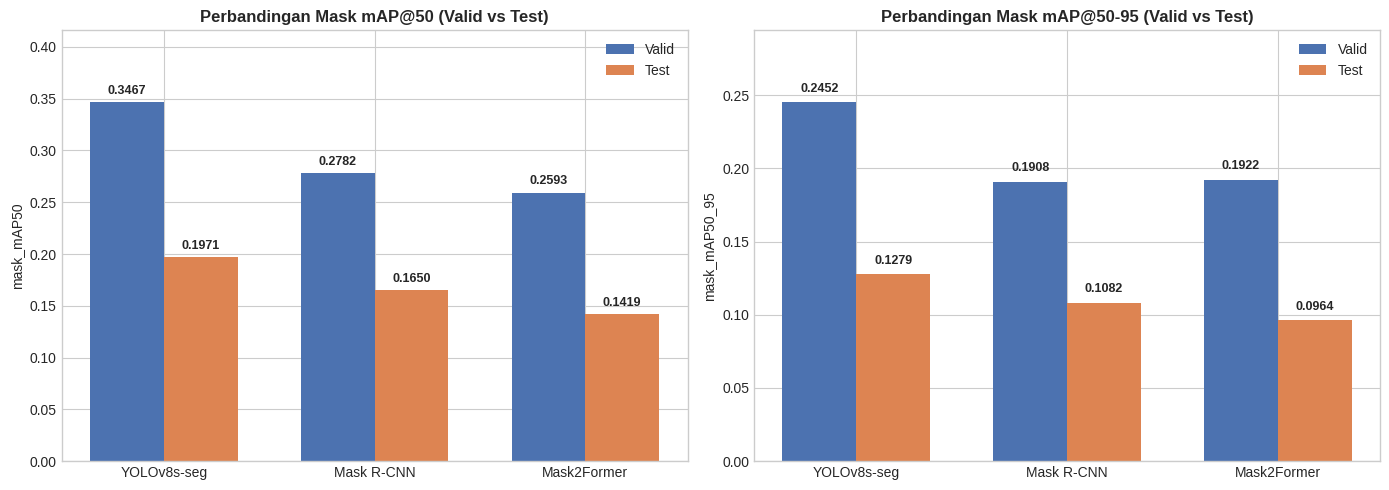

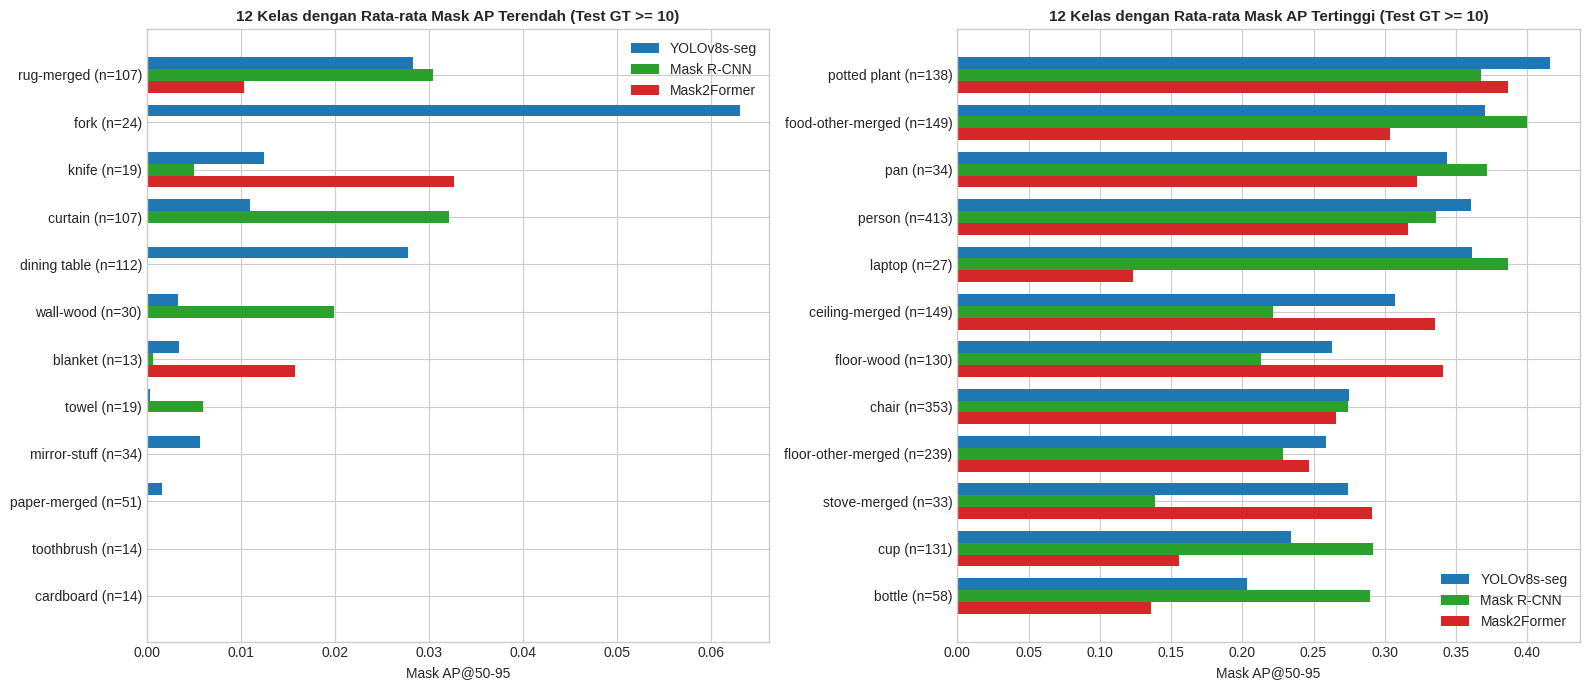

Grafik perbandingan disimpan ke: /content/drive/MyDrive/Visi Komputer/Tugas2/baseline_all_classes/visualizations


In [2]:
# F2. Visualisasi Perbandingan Performa (Valid vs Test) & Top-12 Kelas Terendah vs Terbaik
sum_files = [
    os.path.join(BASE_SAVE_DIR, "01_yolov8s_seg", "eval_summary.csv"),
    os.path.join(BASE_SAVE_DIR, "02_maskrcnn", "eval_summary.csv"),
    os.path.join(BASE_SAVE_DIR, "03_mask2former", "eval_summary.csv"),
]
df_sum = pd.concat([pd.read_csv(f) for f in sum_files], ignore_index=True)

# 1. Bar chart Valid vs Test
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
models = ["YOLOv8s-seg", "Mask R-CNN", "Mask2Former"]
x = np.arange(len(models))
w = 0.35

for ax, metric, title in [
    (axes[0], "mask_mAP50", "Perbandingan Mask mAP@50 (Valid vs Test)"),
    (axes[1], "mask_mAP50_95", "Perbandingan Mask mAP@50-95 (Valid vs Test)"),
]:
    val_scores = [df_sum[(df_sum["model"] == m) & (df_sum["split"] == "valid")][metric].values[0] for m in models]
    test_scores = [df_sum[(df_sum["model"] == m) & (df_sum["split"] == "test")][metric].values[0] for m in models]
    b1 = ax.bar(x - w / 2, val_scores, w, label="Valid", color="#4c72b0")
    b2 = ax.bar(x + w / 2, test_scores, w, label="Test", color="#dd8452")
    for b in list(b1) + list(b2):
        ax.text(b.get_x() + b.get_width() / 2, b.get_height() + 0.005, f"{b.get_height():.4f}", ha="center", va="bottom", fontsize=9, fontweight="bold")
    ax.set_xticks(x)
    ax.set_xticklabels(models)
    ax.set_title(title, fontsize=12, fontweight="bold")
    ax.set_ylabel(metric)
    ax.set_ylim(0, max(val_scores) * 1.2)
    ax.legend()

plt.tight_layout()
out_fig2 = os.path.join(VIZ_DIR, "model_comparison_valid_vs_test.png")
plt.savefig(out_fig2, dpi=200, bbox_inches="tight")
plt.show()

# 2. Visualisasi AP Per Kelas (Test GT >= 10): 12 Terendah vs 12 Terbaik
df_cls = pd.read_csv(os.path.join(BASE_SAVE_DIR, "combined_per_class_ap_test.csv"))
df_act = df_cls[df_cls["gt_instances"] >= 10].copy()

hardest12 = df_act.sort_values("mean_ap", ascending=True).head(12)
easiest12 = df_act.sort_values("mean_ap", ascending=False).head(12).iloc[::-1]

fig, axes = plt.subplots(1, 2, figsize=(16, 7))
for ax, sub_df, title in [
    (axes[0], hardest12, "12 Kelas dengan Rata-rata Mask AP Terendah (Test GT >= 10)"),
    (axes[1], easiest12, "12 Kelas dengan Rata-rata Mask AP Tertinggi (Test GT >= 10)"),
]:
    y = np.arange(len(sub_df))
    h = 0.25
    ax.barh(y + h, sub_df["yolo_ap"], height=h, label="YOLOv8s-seg", color="#1f77b4")
    ax.barh(y, sub_df["mrcnn_ap"], height=h, label="Mask R-CNN", color="#2ca02c")
    ax.barh(y - h, sub_df["m2f_ap"], height=h, label="Mask2Former", color="#d62728")
    labels = [f"{r['class_name']} (n={int(r['gt_instances'])})" for _, r in sub_df.iterrows()]
    ax.set_yticks(y)
    ax.set_yticklabels(labels)
    ax.set_xlabel("Mask AP@50-95")
    ax.set_title(title, fontsize=11, fontweight="bold")
    ax.legend()

plt.tight_layout()
out_fig3 = os.path.join(VIZ_DIR, "per_class_ap_best_vs_hardest.png")
plt.savefig(out_fig3, dpi=200, bbox_inches="tight")
plt.show()
print("Grafik perbandingan disimpan ke:", VIZ_DIR)

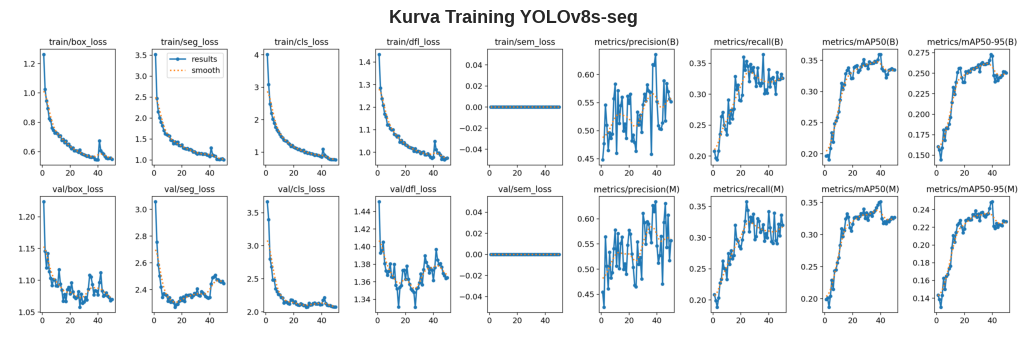

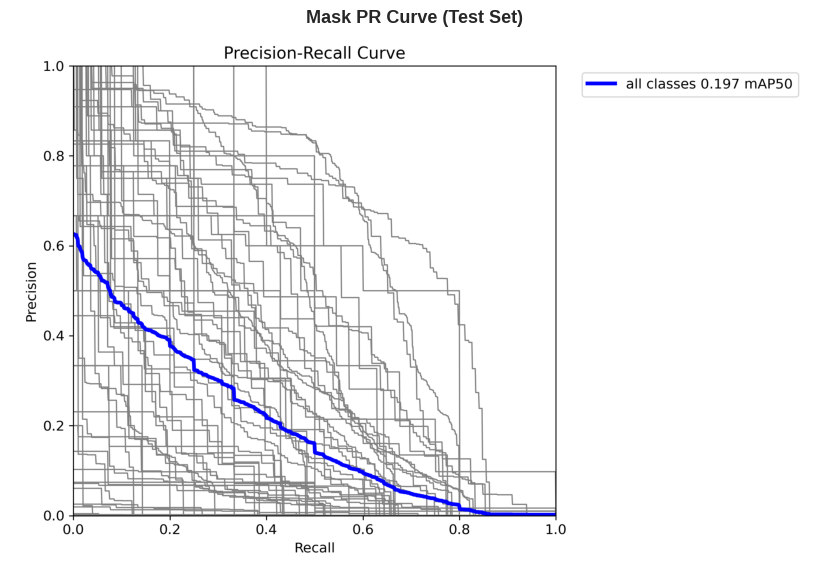

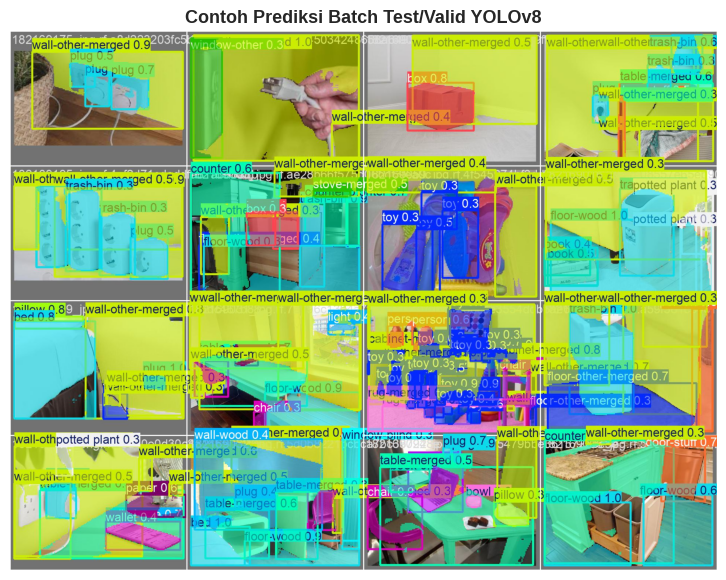

In [3]:
# F3. Tampilkan Grafik Evaluasi Bawaan YOLOv8s-seg
from PIL import Image as PILImage

yolo_imgs = [
    ("Kurva Training YOLOv8s-seg", os.path.join(BASE_SAVE_DIR, "01_yolov8s_seg", "train", "results.png")),
    ("Mask PR Curve (Test Set)", os.path.join(BASE_SAVE_DIR, "01_yolov8s_seg", "eval_test", "MaskPR_curve.png")),
    ("Contoh Prediksi Batch Test/Valid YOLOv8", os.path.join(BASE_SAVE_DIR, "01_yolov8s_seg", "train", "val_batch0_pred.jpg")),
]

for title, p in yolo_imgs:
    if os.path.exists(p):
        plt.figure(figsize=(13, 7))
        plt.imshow(PILImage.open(p))
        plt.title(title, fontsize=13, fontweight="bold")
        plt.axis("off")
        plt.show()
    else:
        print("File tidak ditemukan:", p)

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
Masukkan Roboflow API Key untuk download dataset_coco (karena runtime baru): ··········
loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to /content/dataset_coco in coco-segmentation:: 100%|██████████| 930/930 [00:00<00:00, 3568.19it/s]


loading annotations into memory...
Done (t=0.13s)
creating index...
index created!
loading annotations into memory...
Done (t=0.08s)
creating index...
index created!


Loading weights:   0%|          | 0/556 [00:00<?, ?it/s]

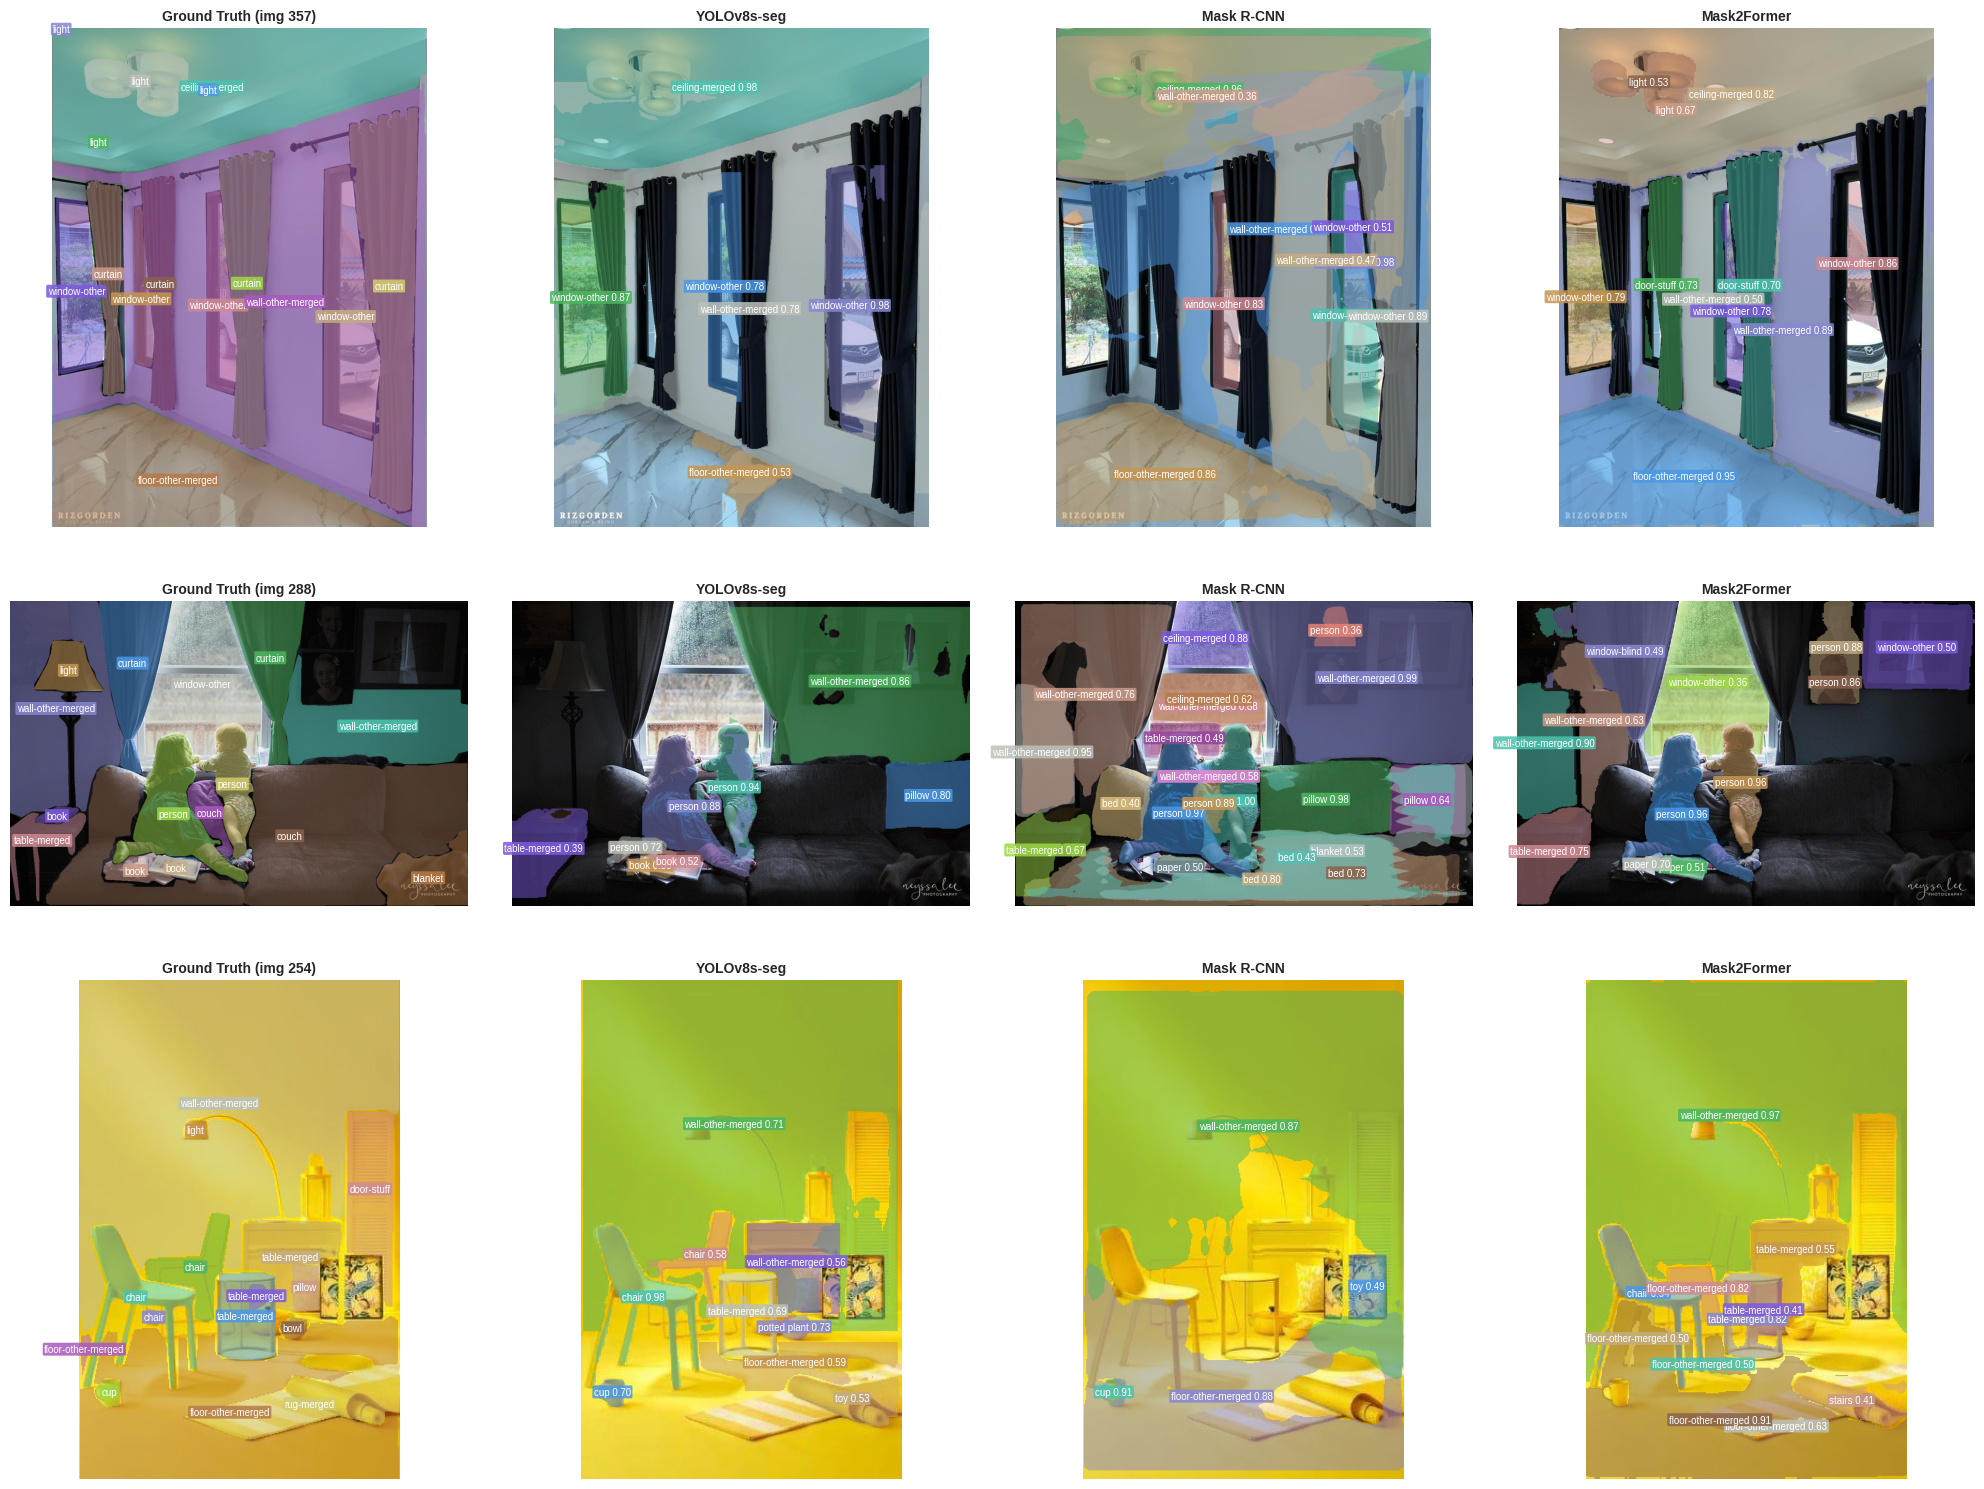

Visualisasi prediksi disimpan ke: /content/drive/MyDrive/Visi Komputer/Tugas2/baseline_all_classes/visualizations/sample_predictions_comparison.png


In [4]:
# F4. Visualisasi Ground Truth vs YOLOv8s-seg vs Mask R-CNN vs Mask2Former
import gc
import importlib.util
import subprocess
import sys

for _pkg in ["roboflow", "ultralytics", "transformers", "pycocotools"]:
    if importlib.util.find_spec(_pkg) is None:
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", _pkg])

import torch
import torchvision
from PIL import Image, ImageOps
from torchvision.transforms import functional as TF
from torchvision.models.detection.mask_rcnn import MaskRCNN_ResNet50_FPN_V2_Weights, MaskRCNNPredictor
from torchvision.models.detection.faster_rcnn import FastRCNNPredictor
from pycocotools.coco import COCO
from ultralytics import YOLO
from transformers import Mask2FormerImageProcessor, Mask2FormerForUniversalSegmentation

COCO_DIR = "/content/dataset_coco"
if not os.path.exists(os.path.join(COCO_DIR, "test", "_annotations.coco.json")):
    from getpass import getpass
    from roboflow import Roboflow
    api_key = getpass("Masukkan Roboflow API Key untuk download dataset_coco (karena runtime baru): ")
    rf = Roboflow(api_key=api_key)
    dataset_coco = rf.workspace("panopticindoor").project("panoptic-indoor-segmentation").version(5).download("coco-segmentation", location=COCO_DIR)

def align_img(img_path, info):
    img = Image.open(img_path)
    expected = (int(info["width"]), int(info["height"]))
    if img.size == expected:
        return img.convert("RGB")
    img_t = ImageOps.exif_transpose(img)
    if img_t.size == expected:
        return img_t.convert("RGB")
    return img_t.convert("RGB").resize(expected, Image.BILINEAR)

def draw_masks(ax, img_np, masks, labels, scores=None, title=""):
    rng = np.random.default_rng(42)
    overlay = img_np.copy().astype(np.float32)
    text_items = []
    for idx, (m, lbl) in enumerate(zip(masks, labels)):
        color = rng.integers(60, 235, size=3, dtype=np.int32)
        mask_bool = m > 0.5
        if mask_bool.sum() == 0:
            continue
        overlay[mask_bool] = overlay[mask_bool] * 0.5 + color * 0.5
        ys, xs = np.where(mask_bool)
        cy, cx = int(np.mean(ys)), int(np.mean(xs))
        txt = f"{lbl}" if scores is None else f"{lbl} {scores[idx]:.2f}"
        text_items.append((cx, cy, txt, tuple((color / 255.0).tolist())))
    ax.imshow(overlay.astype(np.uint8))
    for cx, cy, txt, col in text_items:
        ax.text(cx, cy, txt, fontsize=7, color="white", ha="center", va="center",
                bbox=dict(boxstyle="round,pad=0.15", facecolor=col, alpha=0.85, edgecolor="none"))
    ax.set_title(title, fontsize=10, fontweight="bold")
    ax.axis("off")

coco_test = COCO(os.path.join(COCO_DIR, "test", "_annotations.coco.json"))
train_json = os.path.join(COCO_DIR, "train", "_annotations.coco.json")
coco_ref = COCO(train_json) if os.path.exists(train_json) else coco_test
cat_ids = sorted(coco_ref.getCatIds())
label2cat_mr = {i + 1: cid for i, cid in enumerate(cat_ids)}
label2cat_m2f = {i: cid for i, cid in enumerate(cat_ids)}

# Pilih 3 gambar test yang memiliki cukup banyak objek (mis. 6-15 anotasi) agar visualisasinya kaya
img_candidates = []
for iid in coco_test.getImgIds():
    n_ann = len(coco_test.getAnnIds(imgIds=iid))
    if 6 <= n_ann <= 15:
        img_candidates.append((n_ann, iid))
img_candidates.sort(reverse=True)
sample_ids = [x[1] for x in img_candidates[:3]] if len(img_candidates) >= 3 else coco_test.getImgIds()[:3]

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Load ketiga model terbaik dari Drive
yolo_best = YOLO(os.path.join(BASE_SAVE_DIR, "01_yolov8s_seg", "train", "weights", "best.pt"))

mr_best = torchvision.models.detection.maskrcnn_resnet50_fpn_v2(weights=None, weights_backbone=None)
mr_best.roi_heads.box_predictor = FastRCNNPredictor(mr_best.roi_heads.box_predictor.cls_score.in_features, len(cat_ids) + 1)
mr_best.roi_heads.mask_predictor = MaskRCNNPredictor(mr_best.roi_heads.mask_predictor.conv5_mask.in_channels, 256, len(cat_ids) + 1)
mr_best.load_state_dict(torch.load(os.path.join(BASE_SAVE_DIR, "02_maskrcnn", "best_maskrcnn.pth"), map_location=device))
mr_best.to(device).eval()

m2f_dir = os.path.join(BASE_SAVE_DIR, "03_mask2former", "best_mask2former")
m2f_proc = Mask2FormerImageProcessor.from_pretrained(m2f_dir)
m2f_best = Mask2FormerForUniversalSegmentation.from_pretrained(m2f_dir).to(device).eval()

fig, axes = plt.subplots(len(sample_ids), 4, figsize=(20, 5 * len(sample_ids)))
if len(sample_ids) == 1:
    axes = np.expand_dims(axes, axis=0)

CONF_THRESH = 0.35

for row_idx, iid in enumerate(sample_ids):
    info = coco_test.loadImgs(iid)[0]
    img_pil = align_img(os.path.join(COCO_DIR, "test", info["file_name"]), info)
    img_np = np.array(img_pil)
    w, h = img_pil.size

    # 1) Ground Truth
    gt_anns = coco_test.loadAnns(coco_test.getAnnIds(imgIds=iid))
    gt_masks, gt_labels = [], []
    for a in gt_anns:
        try:
            m = coco_test.annToMask(a)
            if m.shape == (h, w) and m.sum() > 0:
                gt_masks.append(m)
                gt_labels.append(coco_test.cats[a["category_id"]]["name"])
        except Exception:
            pass
    draw_masks(axes[row_idx, 0], img_np, gt_masks, gt_labels, title=f"Ground Truth (img {iid})")

    # 2) YOLOv8s-seg
    y_res = yolo_best.predict(img_np, conf=CONF_THRESH, verbose=False)[0]
    y_masks, y_labels, y_scores = [], [], []
    if y_res.masks is not None:
        raw_m = y_res.masks.data.cpu().numpy()
        for m, c, sc in zip(raw_m, y_res.boxes.cls.cpu().numpy(), y_res.boxes.conf.cpu().numpy()):
            m_rs = np.array(Image.fromarray((m > 0.5).astype(np.uint8) * 255).resize((w, h), Image.NEAREST)) > 127
            y_masks.append(m_rs)
            y_labels.append(yolo_best.names[int(c)])
            y_scores.append(float(sc))
    draw_masks(axes[row_idx, 1], img_np, y_masks, y_labels, y_scores, title="YOLOv8s-seg")

    # 3) Mask R-CNN
    with torch.no_grad():
        mr_out = mr_best([TF.to_tensor(img_pil).to(device)])[0]
    mr_masks, mr_labels, mr_scores = [], [], []
    for sc, lb, mk in zip(mr_out["scores"].cpu().numpy(), mr_out["labels"].cpu().numpy(), mr_out["masks"].cpu().numpy()):
        if sc >= CONF_THRESH and int(lb) in label2cat_mr:
            mr_masks.append(mk[0] > 0.5)
            mr_labels.append(coco_test.cats[label2cat_mr[int(lb)]]["name"])
            mr_scores.append(float(sc))
    draw_masks(axes[row_idx, 2], img_np, mr_masks, mr_labels, mr_scores, title="Mask R-CNN")

    # 4) Mask2Former
    inp = m2f_proc(images=[img_pil], return_tensors="pt")
    with torch.no_grad():
        m2f_out = m2f_best(pixel_values=inp["pixel_values"].to(device), pixel_mask=inp["pixel_mask"].to(device))
    m2f_res = m2f_proc.post_process_instance_segmentation(m2f_out, threshold=CONF_THRESH, target_sizes=[(h, w)])[0]
    seg_arr = m2f_res["segmentation"].cpu().numpy()
    m2f_masks, m2f_labels, m2f_scores = [], [], []
    for sinfo in m2f_res["segments_info"]:
        lbl = int(sinfo["label_id"])
        if lbl in label2cat_m2f:
            bm = seg_arr == sinfo["id"]
            if bm.sum() > 0:
                m2f_masks.append(bm)
                m2f_labels.append(coco_test.cats[label2cat_m2f[lbl]]["name"])
                m2f_scores.append(float(sinfo["score"]))
    draw_masks(axes[row_idx, 3], img_np, m2f_masks, m2f_labels, m2f_scores, title="Mask2Former")

plt.tight_layout()
out_fig4 = os.path.join(VIZ_DIR, "sample_predictions_comparison.png")
plt.savefig(out_fig4, dpi=200, bbox_inches="tight")
plt.show()
print("Visualisasi prediksi disimpan ke:", out_fig4)

del yolo_best, mr_best, m2f_best
gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()